# Phase 2 — Task performance of projected quantum kernels

Phases 1 and 1b studied **concentration** (how much each qubit's state still varies across inputs). Phase 2 asks whether that matters for **classification**.

**Kernel.** For an 8-qubit ZZ re-uploading feature map, the projected kernel compares single-qubit reduced states:
$$k(x,x')=\exp\Big(-\gamma\sum_{k=1}^{8}\lVert\rho_k(x)-\rho_k(x')\rVert_F^2\Big),$$
used in an SVM. Factors varied: interaction graph (11 families), layers L ∈ {1, 2}, bandwidth c ∈ {0.3, 0.6, 1.0}, and, for graphs with unequal degrees, **which feature goes on which qubit**.

**Frozen hypotheses** (from `phase2_frozen.json`):
* **P1** per-qubit concentration predicts usefulness: mean V vs test macro-F1, Spearman ρ > 0 (p < 0.05) in ≥ 2 of 3 tasks at N = 1000.
* **P2** placing the most important features on the lowest-degree qubits beats placing them on the highest-degree qubits in ≥ 70% of paired comparisons.
* **P3** (descriptive) the validation-selected projected kernel vs RBF-SVM and the best classical model, on identical training samples and test rows.

| Section | Content | Checkpoint |
|---|---|---|
| 1 | Configuration, freeze and code-hash verification | All verified |
| 2 | Data: frozen 8-feature views, fixed validation and test subsets | Sizes printed |
| 3 | Simulator (unchanged) + checks | Three PASS lines |
| 4 | Experiment: projected kernels and classical comparators | Results CSV, 0 failed fits |
| 5 | P1, P2, P3 and verdict; figures | Verdict printed |

Run `MODE = "smoke"` first (synthetic data, about 1 minute), then `MODE = "run"`. Edit nothing but the MODE line.

## 1. Configuration and freeze verification

In [7]:
from pathlib import Path
import os, json, hashlib, time, itertools, warnings
import numpy as np, pandas as pd
warnings.filterwarnings("ignore")

MODE = "run"#"smoke"             # "smoke" -> synthetic data, tiny grid | "run" -> the frozen Phase 2 experiment
ROOT = Path(os.environ.get("PQK_ROOT", Path.cwd() / "pqk-nids"))
NOTEBOOK = Path(os.environ.get("PQK_P2_NOTEBOOK", Path.cwd() / "phase2_task_performance.ipynb"))
N_JOBS = int(os.environ.get("PQK_N_JOBS", max(1, (os.cpu_count() or 2) - 1)))
PHASE0_MODE = "quick"; GLOBAL_SEED = 20261001
REDUCED = os.environ.get("PQK_P2_REDUCED") == "1"     # developer test switch: a reduced grid is NEVER a valid result
RES = ROOT / "results" / "phase2" / (MODE + ("_REDUCED_INVALID" if REDUCED else "")); RES.mkdir(parents=True, exist_ok=True)

def sha(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(1 << 20), b""): h.update(b)
    return h.hexdigest()
def code_hash(path):
    nb = json.loads(Path(path).read_text()); src = []
    for c in nb["cells"]:
        if c["cell_type"] == "code":
            s = "".join(c["source"]) if isinstance(c["source"], list) else c["source"]
            src.append("\n".join(l for l in s.splitlines() if not l.strip().startswith("MODE =")))
    return hashlib.sha256("\n#----\n".join(src).encode()).hexdigest()

if MODE == "run":
    F2 = ROOT / "phase2_freeze" / "phase2_frozen.json"; assert F2.exists(), "No Phase 2 freeze. Run freeze_phase2.py first."
    t2 = F2.read_text(); assert hashlib.sha256(t2.encode()).hexdigest() == (F2.parent / "phase2_frozen.json.sha256").read_text().split()[0], "Phase 2 freeze modified"
    FZ2 = json.loads(t2)
    F1 = ROOT / "phase1_freeze" / "phase1_frozen_inputs.json"; t1 = F1.read_text()
    assert hashlib.sha256(t1.encode()).hexdigest() == FZ2["builds_on"]["phase1_freeze_sha256"], "Phase 1 freeze differs"
    FZ1 = json.loads(t1)
    bad = [k for k, v in FZ1["file_sha256"].items() if sha(ROOT / k) != v]; assert not bad, f"Inputs changed since the Phase 1 freeze: {bad}"
    assert NOTEBOOK.exists(), f"Save this notebook as {NOTEBOOK} (or set PQK_P2_NOTEBOOK)"
    assert code_hash(NOTEBOOK) == FZ2["notebook_code_sha256"], "Notebook code differs from the frozen code (only MODE may change). Save and re-check."
    D = FZ2["design"]
    TASKS, NS, SEEDS = D["tasks"], D["training_sizes"], D["seeds"]
    GRAPHS, LAYERS, BANDWIDTHS, HETERO = D["graphs"], D["layers"], D["bandwidths"], D["heterogeneous_graphs"]
    print(f"Phase 2 freeze verified (created {FZ2['created']}); inputs unchanged; notebook code matches the frozen hash.")
else:
    FZ1 = FZ2 = None
    TASKS = {"synthetic:binary": "raw8"}; NS, SEEDS = [250], [0, 1]
    GRAPHS, LAYERS, BANDWIDTHS, HETERO = ["empty", "ring", "star", "complete"], [1], [0.6], ["star"]
if REDUCED:
    NS, SEEDS, GRAPHS, LAYERS, BANDWIDTHS = [250, 1000], [0], GRAPHS[:4] + ["star"], [1], [0.6]
    print("WARNING: REDUCED developer grid. These results are not valid and must not be reported.")
ASSIGN = ["rank", "top_to_low_degree", "top_to_high_degree"]
GAMMA_MULT, C_GRID = [0.5, 1.0, 2.0], [1, 10, 100]
VAL_SIZE, TEST_SIZE = 2000, 4000
print(f"MODE={MODE}  tasks={list(TASKS)}  N={NS}  seeds={SEEDS}  graphs={len(GRAPHS)}  L={LAYERS}  c={BANDWIDTHS}  N_JOBS={N_JOBS}")
print("CHECKPOINT 1: configuration ready.")

Phase 2 freeze verified (created 2026-10-06 22:28:24 EDT); inputs unchanged; notebook code matches the frozen hash.
MODE=run  tasks=['fashion_mnist:binary', 'nf_unsw_nb15_v2:binary', 'unsw_nb15:binary']  N=[250, 1000, 4000]  seeds=[0, 1, 2]  graphs=11  L=[1, 2]  c=[0.3, 0.6, 1.0]  N_JOBS=15
CHECKPOINT 1: configuration ready.


## 2. Data
The frozen 8-feature views from Phase 0 (PCA-8 for Fashion-MNIST, MI-8 for both security datasets). Validation: 2,000 stratified rows (seed 0). Test: up to 4,000 stratified rows of the clean test split (seed 20261001), **the same rows for every model**. Training samples use the Phase 0 sampler with seeds 0, 1, 2.

In [8]:
import joblib
def signed_log1p(X):   # needed to unpickle the Phase 0 preprocessors
    return np.sign(X) * np.log1p(np.abs(X))
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.kernel_approximation import RBFSampler
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.utils.class_weight import compute_sample_weight
import xgboost as xgb, lightgbm as lgb

def grid(model, d):
    if model == "lr":   return [dict(C=c) for c in [0.1, 1, 10]]
    if model == "svm":  return [dict(C=c, gm=g) for c in [1, 10] for g in [0.3, 1, 3]]
    if model == "rff":  return [dict(C=c, gm=g) for c in [1, 10] for g in [0.3, 1, 3]]
    if model == "rf":   return [dict(max_depth=m) for m in [None, 20]]
    if model == "xgb":  return [dict(max_depth=m) for m in [6, 10]]
    if model == "lgbm": return [dict(num_leaves=n) for n in [31, 127]]
    if model == "mlp":  return [dict(alpha=a) for a in [1e-4, 1e-3]]

def build(model, hp, seed, Xtr, ytr):
    g0 = 1.0 / (Xtr.shape[1] * max(float(Xtr.var()), 1e-12))
    if model == "lr":   return LogisticRegression(C=hp["C"], class_weight="balanced", max_iter=3000), None
    if model == "svm":  return SVC(C=hp["C"], gamma=hp["gm"] * g0, class_weight="balanced", random_state=seed), None
    if model == "rff":  return Pipeline([("rff", RBFSampler(gamma=hp["gm"] * g0, n_components=1000, random_state=seed)),
                                          ("lr", LogisticRegression(C=hp["C"], class_weight="balanced", max_iter=3000))]), None
    if model == "rf":   return RandomForestClassifier(n_estimators=300, max_depth=hp["max_depth"], class_weight="balanced", n_jobs=1, random_state=seed), None
    if model == "xgb":  return xgb.XGBClassifier(n_estimators=400, max_depth=hp["max_depth"], learning_rate=0.1, tree_method="hist",
                                                 n_jobs=1, random_state=seed), compute_sample_weight("balanced", ytr)
    if model == "lgbm": return lgb.LGBMClassifier(n_estimators=400, num_leaves=hp["num_leaves"], learning_rate=0.05, class_weight="balanced",
                                                  n_jobs=1, random_state=seed, verbose=-1), None
    if model == "mlp":  return MLPClassifier(hidden_layer_sizes=(128, 64), alpha=hp["alpha"], early_stopping=True, max_iter=300, random_state=seed), None



def sample_n(y, n, seed, min_per_class=2):
    # proportional stratified sample of size ~n with at least `min_per_class` per class present
    rng = np.random.default_rng(seed); cls, cnt = np.unique(y, return_counts=True)
    if n >= len(y): return rng.permutation(len(y))
    take = np.maximum(np.minimum(cnt, min_per_class), np.round(n * cnt / cnt.sum()).astype(int)); take = np.minimum(take, cnt)
    idx = np.concatenate([rng.choice(np.flatnonzero(y == c), t, replace=False) for c, t in zip(cls, take)])
    return rng.permutation(idx)

DATA = {}
if MODE == "run":
    PROC = ROOT / "data" / "processed"; ranks = json.load(open(ROOT / "results" / "phase0" / PHASE0_MODE / "feature_rankings.json"))
    for task, view in TASKS.items():
        ds = task.split(":")[0]; pre = joblib.load(PROC / ds / f"preprocessor_{PHASE0_MODE}.joblib"); out = {}
        for split in ["train", "val", "test"]:
            fr = pd.read_parquet(PROC / ds / f"{split}_{PHASE0_MODE}.parquet"); M = pre["ct"].transform(fr[pre["cols"]])
            if view == "pca8":
                pca, sc = joblib.load(PROC / ds / f"pca_{PHASE0_MODE}.joblib")[8]; X = sc.transform(pca.transform(M))
            else:
                names = list(pre["names"]); feats = ranks[ds]["mi"][:8]
                assert feats == FZ1["feature_definitions"][f"{ds}/mi8"], "MI-8 list differs from the freeze"
                X = np.asarray(M[:, [names.index(f) for f in feats]])
            out[split] = (np.asarray(X, dtype=np.float64), fr["y_bin"].to_numpy().astype(int))
        DATA[task] = out
else:
    rng = np.random.default_rng(0); out = {}
    for split, n in [("train", 3000), ("val", 600), ("test", 600)]:
        X = rng.standard_normal((n, 8)); y = ((X[:, 0] * X[:, 1] + 0.7 * X[:, 2] + 0.3 * rng.standard_normal(n)) > 0).astype(int)
        out[split] = (X, y)
    DATA["synthetic:binary"] = out

SUB = {}
for task, d in DATA.items():
    iv = sample_n(d["val"][1], VAL_SIZE, 0); it = sample_n(d["test"][1], TEST_SIZE, GLOBAL_SEED)
    tr_idx = {(N, s): sample_n(d["train"][1], min(N, len(d["train"][1])), s) for N in NS for s in SEEDS}
    SUB[task] = dict(val=iv, test=it, train=tr_idx)
    print(f"{task:26s} train pool={len(d['train'][1]):>7,}  val subset={len(iv):,}  test subset={len(it):,}  "
          f"test attack/positive share={d['test'][1][it].mean():.3f}")
print("CHECKPOINT 2: data and fixed subsets ready.")

fashion_mnist:binary       train pool=  9,600  val subset=2,000  test subset=2,000  test attack/positive share=0.500
nf_unsw_nb15_v2:binary     train pool= 62,412  val subset=2,000  test subset=4,000  test attack/positive share=0.337
unsw_nb15:binary           train pool= 80,648  val subset=2,000  test subset=4,000  test attack/positive share=0.360
CHECKPOINT 2: data and fixed subsets ready.


## 3. Simulator (identical to Phases 1 and 1b) and checks

In [9]:
def zsigns(n):
    D = 2 ** n
    bits = (np.arange(D)[:, None] >> (n - 1 - np.arange(n))) & 1   # qubit 0 = most significant bit
    return 1 - 2 * bits                                            # (D, n), Z eigenvalues +1/-1

def simulate(X, edges, L, c):
    # X: (N, n) features. Returns (N, 2**n) states U(x)|0...0>.
    N, n = X.shape; D = 2 ** n
    psi = np.zeros((N, D), dtype=complex); psi[:, 0] = 1.0
    if edges:
        s = zsigns(n); S = np.stack([s[:, i] * s[:, j] for i, j in edges], 1)          # (D, E)
        W = np.stack([X[:, i] * X[:, j] for i, j in edges], 1)                         # (N, E)
        phase = np.exp(-0.5j * (c ** 2) * (W @ S.T))                                    # (N, D)
    for _ in range(L):
        for k in range(n):
            th = c * X[:, k]; co = np.cos(th / 2)[:, None, None]; si = np.sin(th / 2)[:, None, None]
            p = psi.reshape(N, 2 ** k, 2, 2 ** (n - k - 1))
            a0 = p[:, :, 0, :].copy(); a1 = p[:, :, 1, :].copy()
            p[:, :, 0, :] = co * a0 - si * a1
            p[:, :, 1, :] = si * a0 + co * a1
        if edges:
            psi = psi * phase
    return psi

def bloch(psi, n):
    N = psi.shape[0]; R = np.empty((N, n, 3))
    for k in range(n):
        p = psi.reshape(N, 2 ** k, 2, 2 ** (n - k - 1)); a0, a1 = p[:, :, 0, :], p[:, :, 1, :]
        r01 = (a0 * a1.conj()).sum((1, 2))
        R[:, k] = np.stack([2 * r01.real, -2 * r01.imag, (abs(a0) ** 2).sum((1, 2)) - (abs(a1) ** 2).sum((1, 2))], 1)
    return R

def dense_state(x, edges, L, c):
    n = len(x); I = np.eye(2)
    def on(k, g):
        out = np.array([[1.0]])
        for q in range(n): out = np.kron(out, g if q == k else I)
        return out
    U = np.eye(2 ** n, dtype=complex)
    for _ in range(L):
        for k in range(n):
            t = c * x[k]; U = on(k, np.array([[np.cos(t / 2), -np.sin(t / 2)], [np.sin(t / 2), np.cos(t / 2)]])) @ U
        for i, j in edges:
            ZZ = on(i, np.diag([1., -1.])) @ on(j, np.diag([1., -1.]))
            U = (np.cos(c ** 2 * x[i] * x[j] / 2) * np.eye(2 ** n) - 1j * np.sin(c ** 2 * x[i] * x[j] / 2) * ZZ) @ U
    v = np.zeros(2 ** n, dtype=complex); v[0] = 1; return U @ v


import networkx as nx
def families(n, seed=GLOBAL_SEED):
    F = {"empty": [], "chain": [(i, i + 1) for i in range(n - 1)], "ring": [(i, (i + 1) % n) for i in range(n)],
         "star": [(0, i) for i in range(1, n)], "complete": [(i, j) for i in range(n) for j in range(i + 1, n)],
         "wheel": [(0, i) for i in range(1, n)] + [(i, i % (n - 1) + 1) for i in range(1, n)]}
    h = n // 2
    F["double_star"] = [(0, 1)] + [(0, i) for i in range(2, h + 1)] + [(1, i) for i in range(h + 1, n)]
    if n % 2 == 0: F["matching"] = [(i, i + 1) for i in range(0, n, 2)]
    def cycles(sizes):
        e, s0 = [], 0
        for m in sizes:
            e += [(s0 + i, s0 + (i + 1) % m) for i in range(m)]; s0 += m
        return e
    if n % 4 == 0: F["cycles4"] = cycles([4] * (n // 4))
    if n % 3 == 0: F["triangles"] = cycles([3] * (n // 3))
    F["two_cycles"] = cycles([n // 2, n - n // 2])
    if n % 4 == 0: F["k4s"] = sum(([(b + i, b + j) for i in range(4) for j in range(i + 1, 4)] for b in range(0, n, 4)), [])
    if n % 2 == 0:
        for s in range(seed, seed + 500):
            g = nx.random_regular_graph(3, n, seed=s)
            if nx.is_connected(g): F["regular3"] = sorted(tuple(sorted(e)) for e in g.edges()); break
    for tag, off in [("a", 0), ("b", 1000)]:
        for s in range(seed + off, seed + off + 500):
            g = nx.gnp_random_graph(n, 0.3, seed=s)
            if nx.is_connected(g): F[f"erdos_renyi_{tag}"] = sorted(tuple(sorted(e)) for e in g.edges()); break
        r = np.random.default_rng(seed + off + n)
        g = nx.from_prufer_sequence(list(r.integers(0, n, n - 2)))
        F[f"random_tree_{tag}"] = sorted(tuple(sorted(e)) for e in g.edges())
    out, seen = {}, set()   # drop duplicate edge sets (e.g. two_cycles == cycles4 at n = 8)
    for k, E in F.items():
        key = frozenset(tuple(sorted(e)) for e in E)
        if key not in seen: seen.add(key); out[k] = [tuple(sorted(e)) for e in E]
    return out


CHECKS = {}
t = np.random.default_rng(1).standard_normal((5, 3)); e3 = [(0, 1), (1, 2), (0, 2)]
d = max(np.abs(simulate(t, e3, 2, 0.8)[i] - dense_state(t[i], e3, 2, 0.8)).max() for i in range(5))
CHECKS["dense_check_n3"] = dict(max_abs_diff=float(d), pass_=bool(d < 1e-12))
FAMS = families(8)
missing = [g for g in GRAPHS if g not in FAMS]; assert not missing, f"graph families missing: {missing}"
x = np.random.default_rng(2).standard_normal((3, 8)); ne = max(abs(np.linalg.norm(simulate(x, FAMS[g], 2, 1.0), axis=1) - 1).max() for g in GRAPHS)
CHECKS["normalisation"] = dict(max_norm_error=float(ne), pass_=bool(ne < 1e-12))
def degrees(E, n=8):
    d = np.zeros(n, int)
    for i, j in E: d[i] += 1; d[j] += 1
    return d
def perm_for(E, assign, n=8):
    # perm[q] = feature placed on qubit q; features are in importance order (0 = most important)
    if assign == "rank": return np.arange(n)
    deg = degrees(E, n); order = np.lexsort((np.arange(n), deg if assign == "top_to_low_degree" else -deg))
    perm = np.empty(n, int); perm[order] = np.arange(n); return perm
p = perm_for(FAMS["star"], "top_to_high_degree"); q = perm_for(FAMS["star"], "top_to_low_degree")
CHECKS["assignment"] = dict(star_hub_gets_feature_when_high=int(p[0]), star_hub_gets_feature_when_low=int(q[0]),
                            pass_=bool(p[0] == 0 and q[0] == 7 and sorted(p) == list(range(8))))
for k, v in CHECKS.items():
    print(f"{'PASS' if v['pass_'] else 'FAIL'}  {k}  {({a: b for a, b in v.items() if a != 'pass_'})}")
json.dump(CHECKS, open(RES / "checks.json", "w"), indent=2)
assert all(v["pass_"] for v in CHECKS.values()), "Checks failed: stop."
print("CHECKPOINT 3: simulator verified.")

PASS  dense_check_n3  {'max_abs_diff': 1.1443916996305594e-16}
PASS  normalisation  {'max_norm_error': 2.220446049250313e-16}
PASS  assignment  {'star_hub_gets_feature_when_high': 0, 'star_hub_gets_feature_when_low': 7}
CHECKPOINT 3: simulator verified.


## 4. Experiment
For each task and feature-map configuration (graph, L, c, assignment): compute Bloch-vector features once for every needed row, build projected kernels, tune γ-multiplier and C on the validation subset (seed-0 sample), refit for each seed, and score on the test subset. Comparators (RBF-SVM and the Phase 0 best classical model) use the identical training samples and test rows. Configurations run in parallel; results are appended as they finish, and re-running skips finished work.

In [10]:
from sklearn.svm import SVC
from sklearn.metrics import f1_score, matthews_corrcoef, roc_auc_score
from joblib import Parallel, delayed

def bloch_features(X, E, L, c, perm, batch=2000):
    out = []
    for i in range(0, len(X), batch):
        Xb = X[i:i + batch][:, perm]; out.append(bloch(simulate(Xb, E, L, c), 8).reshape(len(Xb), -1))
    return np.vstack(out)

def proj_dist(A, B):   # sum_k ||rho_k - rho_k'||_F^2 = 0.5 * ||r - r'||^2
    sq = (A ** 2).sum(1)[:, None] + (B ** 2).sum(1)[None, :] - 2 * A @ B.T
    return 0.5 * np.maximum(sq, 0.0)

def scores(y, pred, dec):
    out = dict(macro_f1=f1_score(y, pred, average="macro"), mcc=matthews_corrcoef(y, pred))
    try: out["roc_auc"] = roc_auc_score(y, dec)
    except Exception: out["roc_auc"] = np.nan
    return out

def run_pqk(task, gname, L, c, assign):
    d = DATA[task]; S = SUB[task]; E = FAMS[gname]; perm = perm_for(E, assign)
    need = np.unique(np.concatenate(list(S["train"].values())))
    Ftr_all = np.zeros((len(d["train"][1]), 24)); Ftr_all[need] = bloch_features(d["train"][0][need], E, L, c, perm)
    Fva = bloch_features(d["val"][0][S["val"]], E, L, c, perm); yva = d["val"][1][S["val"]]
    Fte = bloch_features(d["test"][0][S["test"]], E, L, c, perm); yte = d["test"][1][S["test"]]
    deg = degrees(E); rows = []
    for N in NS:
        i0 = S["train"][(N, SEEDS[0])]; F0 = Ftr_all[i0]
        R0 = F0.reshape(len(F0), 8, 3); meanV = float(np.mean([np.trace(np.cov(R0[:, k].T)) for k in range(8)]))
        sub = F0[np.random.default_rng(0).choice(len(F0), min(500, len(F0)), replace=False)]
        med = float(np.median(proj_dist(sub, sub)[np.triu_indices(len(sub), 1)])); g0 = 1.0 / max(med, 1e-12)
        best = (-1, None)
        for gm in GAMMA_MULT:
            Ktr = np.exp(-gm * g0 * proj_dist(F0, F0)); Kva = np.exp(-gm * g0 * proj_dist(Fva, F0))
            for C in C_GRID:
                m = SVC(kernel="precomputed", C=C, class_weight="balanced").fit(Ktr, d["train"][1][i0])
                f = f1_score(yva, m.predict(Kva), average="macro")
                if f > best[0]: best = (f, (gm, C))
        gm, C = best[1]
        for s in SEEDS:
            ii = S["train"][(N, s)]; Fs = Ftr_all[ii]; ys = d["train"][1][ii]
            m = SVC(kernel="precomputed", C=C, class_weight="balanced").fit(np.exp(-gm * g0 * proj_dist(Fs, Fs)), ys)
            Kte = np.exp(-gm * g0 * proj_dist(Fte, Fs)); pred = m.predict(Kte)
            r = dict(task=task, model="pqk", graph=gname, L=L, c=c, assignment=assign, N=N, seed=s, gamma_mult=gm, C=C,
                     val_macro_f1=best[0], meanV=meanV, mean_degree=float(deg.mean()), max_degree=int(deg.max()),
                     density=len(E) / 28, **scores(yte, pred, m.decision_function(Kte)))
            if s == SEEDS[0]: r["pred"] = "".join(map(str, pred))
            rows.append(r)
    return rows

def run_classical(task, model, N):
    d = DATA[task]; S = SUB[task]; yva = d["val"][1][S["val"]]; Xva = d["val"][0][S["val"]]
    Xte = d["test"][0][S["test"]]; yte = d["test"][1][S["test"]]; i0 = S["train"][(N, SEEDS[0])]
    best = (-1, None)
    for hp in grid(model, 8):
        try:
            m, sw = build(model, hp, 0, d["train"][0][i0], d["train"][1][i0])
            m.fit(d["train"][0][i0], d["train"][1][i0], **({"sample_weight": sw} if sw is not None else {}))
            f = f1_score(yva, m.predict(Xva), average="macro")
            if f > best[0]: best = (f, hp)
        except Exception:
            continue
    rows = []
    for s in SEEDS:
        ii = S["train"][(N, s)]; m, sw = build(model, best[1], s, d["train"][0][ii], d["train"][1][ii])
        m.fit(d["train"][0][ii], d["train"][1][ii], **({"sample_weight": sw} if sw is not None else {}))
        pred = m.predict(Xte); dec = m.decision_function(Xte) if hasattr(m, "decision_function") else m.predict_proba(Xte)[:, 1]
        r = dict(task=task, model=("rbf_svm" if model == "svm" else f"ceiling_{model}"), N=N, seed=s, hp=json.dumps(best[1]),
                 val_macro_f1=best[0], **scores(yte, pred, dec))
        if s == SEEDS[0]: r["pred"] = "".join(map(str, pred))
        rows.append(r)
    return rows

JOBS_Q = [(t, g, L, c, a) for t in TASKS for g in GRAPHS for L in LAYERS for c in BANDWIDTHS for a in ASSIGN
          if a == "rank" or g in HETERO]
if MODE == "run":
    ref = FZ1["reference_baselines_phase0"]
    best_model = {(t, N): ref[t][v][str(N)]["best_model"] for t, v in TASKS.items() for N in NS}
else:
    best_model = {(t, N): "xgb" for t in TASKS for N in NS}
JOBS_C = sorted({(t, "svm", N) for t in TASKS for N in NS} | {(t, best_model[(t, N)], N) for t in TASKS for N in NS})

OUTF = RES / "phase2_results.csv"
done_q, done_c = set(), set()
if OUTF.exists():
    prev = pd.read_csv(OUTF, dtype={"pred": str})
    q = prev[prev.model == "pqk"]; done_q = set(zip(q.task, q.graph, q.L, q.c, q.assignment))
    cl = prev[prev.model != "pqk"]; done_c = set(zip(cl.task, cl.model, cl.N))
COLS = ["task", "model", "graph", "L", "c", "assignment", "N", "seed", "gamma_mult", "C", "hp", "val_macro_f1", "meanV",
        "mean_degree", "max_degree", "density", "macro_f1", "mcc", "roc_auc", "pred"]
if OUTF.exists():
    assert list(pd.read_csv(OUTF, nrows=0).columns) == COLS, "phase2_results.csv has an old layout: delete it and rerun"
def save(rows):
    pd.DataFrame(rows).reindex(columns=COLS).to_csv(OUTF, mode="a", header=not OUTF.exists(), index=False)

t0 = time.time()
todo_c = [j for j in JOBS_C if (j[0], "rbf_svm" if j[1] == "svm" else f"ceiling_{j[1]}", j[2]) not in done_c]
out = Parallel(n_jobs=N_JOBS)(delayed(run_classical)(*j) for j in todo_c)
if out: save([r for o in out for r in o])
print(f"classical comparators: {len(todo_c)} jobs ({time.time() - t0:.0f}s)")
todo_q = [j for j in JOBS_Q if (j[0], j[1], j[2], j[3], j[4]) not in done_q]
print(f"projected-kernel configurations: {len(JOBS_Q)} total, {len(todo_q)} to run")
B = max(1, 4 * N_JOBS)
for i in range(0, len(todo_q), B):
    out = Parallel(n_jobs=N_JOBS)(delayed(run_pqk)(*j) for j in todo_q[i:i + B])
    save([r for o in out for r in o])
    print(f"  {min(i + B, len(todo_q))}/{len(todo_q)} configurations ({(time.time() - t0) / 60:.1f} min)")
RAW = pd.read_csv(OUTF, dtype={"pred": str})
print(f"CHECKPOINT 4: {len(RAW)} result rows -> {OUTF}")

classical comparators: 14 jobs (5s)
projected-kernel configurations: 306 total, 306 to run
  60/306 configurations (0.7 min)
  120/306 configurations (1.3 min)
  180/306 configurations (1.8 min)
  240/306 configurations (2.3 min)
  300/306 configurations (2.8 min)
  306/306 configurations (2.9 min)
CHECKPOINT 4: 2796 result rows -> /Users/aakarshetar/Documents/Q-kernel/Phase 0/pqk-nids/results/phase2/run/phase2_results.csv


## 5. Hypotheses P1, P2, comparison P3, verdict

In [11]:
from scipy import stats
RAW = pd.read_csv(OUTF, dtype={"pred": str})
Q = RAW[RAW.model == "pqk"]
A = Q.groupby(["task", "graph", "L", "c", "assignment", "N"]).agg(macro_f1=("macro_f1", "mean"), meanV=("meanV", "first"),
        val_macro_f1=("val_macro_f1", "first"), mean_degree=("mean_degree", "first")).reset_index()
A.to_csv(RES / "pqk_config_summary.csv", index=False)

# P1
p1 = []
for (task, N), g in A[A.assignment == "rank"].groupby(["task", "N"]):
    rho, p = stats.spearmanr(g.meanV, g.macro_f1); p1.append(dict(task=task, N=N, configs=len(g), spearman=round(float(rho), 3), p=float(p),
                                                                   positive_significant=bool(rho > 0 and p < 0.05)))
P1 = pd.DataFrame(p1); P1.to_csv(RES / "P1_concentration_vs_f1.csv", index=False)
nprim = 1000 if 1000 in NS else max(NS)
P1_pass = bool(P1[P1.N == nprim].positive_significant.sum() >= 2)

# P2
lo = A[A.assignment == "top_to_low_degree"].set_index(["task", "graph", "L", "c", "N"]).macro_f1
hi = A[A.assignment == "top_to_high_degree"].set_index(["task", "graph", "L", "c", "N"]).macro_f1
P2 = pd.DataFrame({"low": lo, "high": hi}).dropna(); P2["diff"] = P2.low - P2.high
P2.reset_index().to_csv(RES / "P2_assignment_pairs.csv", index=False)
P2_share = float((P2["diff"] > 0).mean()) if len(P2) else float("nan"); P2_med = float(P2["diff"].median()) if len(P2) else float("nan")
P2_pass = bool(len(P2) and P2_share >= 0.70 and P2_med > 0)

# P3
def boot_diff(y, pa, pb, n=1000, seed=0):
    rng = np.random.default_rng(seed); out = []
    for _ in range(n):
        i = rng.integers(0, len(y), len(y)); out.append(f1_score(y[i], pa[i], average="macro") - f1_score(y[i], pb[i], average="macro"))
    return np.percentile(out, [2.5, 97.5])
p3 = []
for task in TASKS:
    yte = DATA[task]["test"][1][SUB[task]["test"]]
    for N in NS:
        cand = A[(A.task == task) & (A.N == N)].sort_values("val_macro_f1", ascending=False).iloc[0]
        sel = Q[(Q.task == task) & (Q.N == N) & (Q.graph == cand.graph) & (Q.L == cand.L) & (Q.c == cand.c) & (Q.assignment == cand.assignment)]
        C_ = RAW[(RAW.task == task) & (RAW.N == N) & (RAW.model != "pqk")]
        for comp in sorted(C_.model.unique()):
            cc = C_[C_.model == comp]
            pa = np.array(list(sel[sel.seed == SEEDS[0]].pred.iloc[0]), int); pb = np.array(list(cc[cc.seed == SEEDS[0]].pred.iloc[0]), int)
            lo_, hi_ = boot_diff(yte, pa, pb)
            p3.append(dict(task=task, N=N, selected=f"{cand.graph}/L{int(cand.L)}/c{cand.c}/{cand.assignment}", comparator=comp,
                           pqk_macro_f1=round(float(sel.macro_f1.mean()), 4), comparator_macro_f1=round(float(cc.macro_f1.mean()), 4),
                           diff_seed0_ci_lo=round(float(lo_), 4), diff_seed0_ci_hi=round(float(hi_), 4),
                           non_inferior_to_rbf=(bool(lo_ > -0.01) if comp == "rbf_svm" else None)))
P3 = pd.DataFrame(p3); P3.to_csv(RES / "P3_vs_classical.csv", index=False)

summary = dict(mode=MODE + (" (REDUCED, INVALID)" if REDUCED else ""),
               P1=f"{int(P1[P1.N == nprim].positive_significant.sum())}/{P1[P1.N == nprim].shape[0]} tasks with significant positive Spearman at N={nprim}",
               P1_pass=P1_pass, P2=f"{(P2['diff'] > 0).sum() if len(P2) else 0}/{len(P2)} pairs favour top_to_low_degree (share {P2_share:.2f}, median diff {P2_med:+.4f})",
               P2_pass=P2_pass, P3="see P3_vs_classical.csv",
               failed_rows=int(RAW.macro_f1.isna().sum()))
json.dump(summary, open(RES / "verdict.json", "w"), indent=2)
print(P1.to_string(index=False)); print(); print(P3.drop(columns=[]).to_string(index=False))
print("\n" + "=" * 70); print(json.dumps(summary, indent=1))
if MODE == "smoke" or REDUCED:
    print("Smoke / reduced mode: synthetic or reduced data. The verdict only proves the code runs.")

                  task    N  configs  spearman            p  positive_significant
  fashion_mnist:binary  250       66    -0.510 1.246288e-05                 False
  fashion_mnist:binary 1000       66    -0.597 1.200689e-07                 False
  fashion_mnist:binary 4000       66    -0.516 9.183222e-06                 False
nf_unsw_nb15_v2:binary  250       66     0.040 7.508481e-01                 False
nf_unsw_nb15_v2:binary 1000       66    -0.154 2.157327e-01                 False
nf_unsw_nb15_v2:binary 4000       66     0.052 6.796101e-01                 False
      unsw_nb15:binary  250       66    -0.192 1.218938e-01                 False
      unsw_nb15:binary 1000       66     0.260 3.534003e-02                  True
      unsw_nb15:binary 4000       66     0.281 2.222030e-02                  True

                  task    N                         selected  comparator  pqk_macro_f1  comparator_macro_f1  diff_seed0_ci_lo  diff_seed0_ci_hi non_inferior_to_rbf
  fashion_mnist

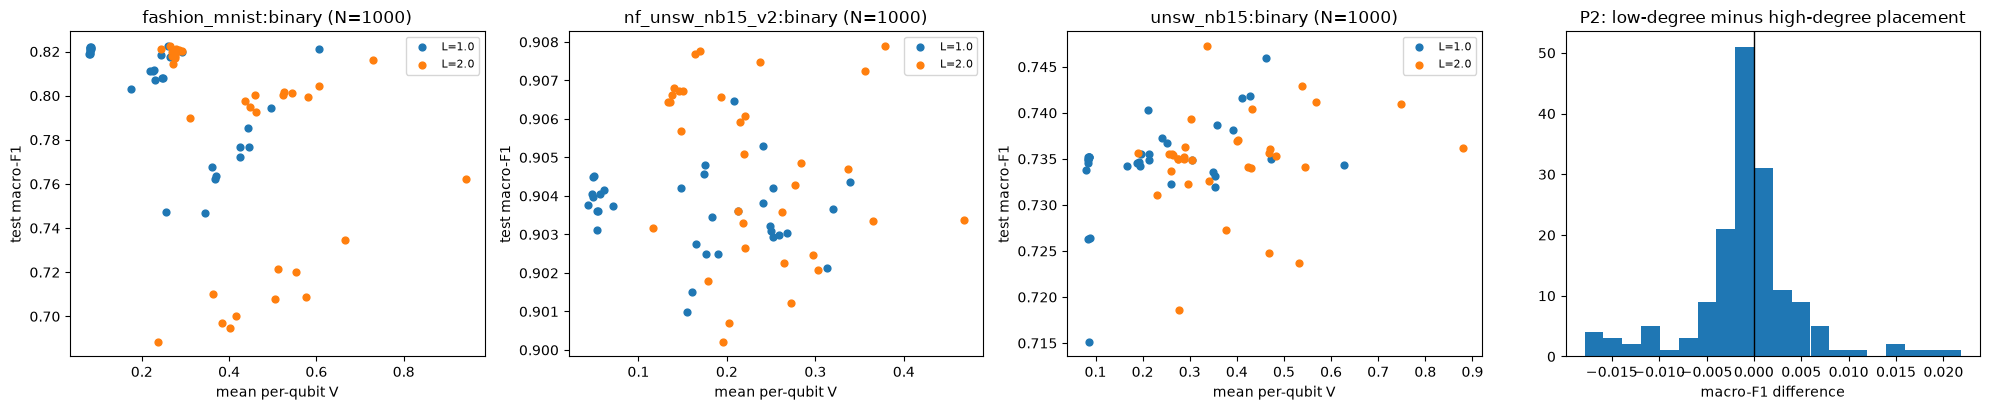

CHECKPOINT 5: verdict and figure saved -> /Users/aakarshetar/Documents/Q-kernel/Phase 0/pqk-nids/results/phase2/run


In [12]:
try:
    import matplotlib.pyplot as plt
    tasks = list(TASKS); fig, ax = plt.subplots(1, len(tasks) + 1, figsize=(5 * (len(tasks) + 1), 4.2))
    ax = np.atleast_1d(ax)
    for i, t in enumerate(tasks):
        g = A[(A.task == t) & (A.N == nprim) & (A.assignment == "rank")]
        for L, gl in g.groupby("L"): ax[i].scatter(gl.meanV, gl.macro_f1, s=24, label=f"L={L}")
        ax[i].set_xlabel("mean per-qubit V"); ax[i].set_ylabel("test macro-F1"); ax[i].set_title(f"{t} (N={nprim})"); ax[i].legend(fontsize=8)
    if len(P2):
        ax[-1].hist(P2["diff"], bins=20); ax[-1].axvline(0, color="k", lw=1)
        ax[-1].set_title("P2: low-degree minus high-degree placement"); ax[-1].set_xlabel("macro-F1 difference")
    plt.tight_layout(); plt.savefig(RES / "phase2_figure.png", dpi=160); plt.show()
except ImportError:
    print("matplotlib not installed: figure skipped")
print("CHECKPOINT 5: verdict and figure saved ->", RES)

## What to send back
Zip the **whole folder** `pqk-nids/results/phase2/run/` (do not upload files one by one) and send it with this executed notebook and `pqk-nids/phase2_freeze/`.